# 3W Coverage

**Project:** Pali Watch

**Notebook:** `3w_coverage.ipynb`

**Author:** Yuseof J

**Created:** 11/11/2026 | **Last updated:** 14/11/2026

## Purpose
This file presents a more coarse historical view of org coverage in Palestine

## Inputs

- `data/raw/boundaries/`: HDX admin boundaries (COD-AB)

## Outputs
- `data/processed/[filename].csv`: what it contains

## Notes and caveats
- Data limitations: data source ends in April 2023, so its completely obsolete for Gaza, and for the West Bank provides only a historical snapshot. This is more of a placeholder in lieu of more recent 3w data

In [2]:
import datetime
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt

In [3]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
    
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

CRS = 'EPSG:4326'

## Data imports / exports

In [31]:
# import paths
PATH_TO_ADMIN_BOUNDARIES = f'{RAW}/pse_admin_boundaries.shp/pse_admin2.shp'
PATH_TO_3W_COVERAGE = f'{RAW}/3w-coverage/pse-who-what-where-3w.xlsx'

# export paths
PATH_TO_GEOLOCATED_EVENTS_GPKG = f'{PROCESSED}/acled/conflict_events_geolocated.gpkg'
PATH_TO_GEOLOCATED_EVENTS_DF = f'{PROCESSED}/acled/conflict_events_geolocated.csv'

# import data
df_3w = pd.read_excel(PATH_TO_3W_COVERAGE)
gdf_boundaries = gpd.read_file(PATH_TO_ADMIN_BOUNDARIES)

## Preprocessing

In [36]:
# remove second row 
if df_3w.iloc[0].Cluster == "#sector+name":
    df_3w.drop([0], inplace=True)

In [38]:
# ensure matching governorate names
set_boundary_govs = set(gdf_boundaries.adm2_name.unique())
set_3w_govs = set(df_3w.Governorates.unique())
set_unaccounted = set_boundary_govs - set_3w_govs
print(f"The following govs are mismatched/unaccounted for: {set_unaccounted}")

dict_unaccounted_govs = {
    'Gaza North': 'North Gaza', 
    'Qalqiliya': 'Qalqilya', 
    'Khan Yunis': 'Khan Younis', 
    'Deir Al-Balah (Middle area)': 'Deir Al-Balah' 
}

# ensure all mismatched gov names are accounted for
set_unaccounted - set(dict_unaccounted_govs.values())
assert(set_unaccounted - set(dict_unaccounted_govs.values()) == set())
print("All governorates successfully updated")

# replace mismatched gov names
df_3w.replace(dict_unaccounted_govs, inplace=True)

The following govs are mismatched/unaccounted for: set()
All governorates successfully updated


## Governorate Aggregates

In [39]:
df_3w.head()

,Cluster,Organization,Partners,Activity,Governorates,Communities
1,Food Security,Union of Agricultural Work Committees,NaN,Rehabilitation and provision of productive ass...,Gaza,Al Mughraqa (Abu Middein); Gaza;
2,Food Security,Union of Agricultural Work Committees,NaN,Rehabilitation and provision of productive ass...,Deir Al-Balah,Az Zawayda; Deir al Balah; Wadi as Salqa;
3,Food Security,Union of Agricultural Work Committees,NaN,Rehabilitation and provision of productive ass...,North Gaza,Beit Hanoun; Beit Lahiya; Jabalia; Siafa;
4,Food Security,Union of Agricultural Work Committees,NaN,Rehabilitation and provision of productive ass...,Deir Al-Balah,An Nuseirat Camp; Az Zawayda; Wadi as Salqa;
5,Food Security,Oxfam,Palestinian Economic and Social Development Ce...,Rehabilitation and provision of productive ass...,Khan Younis,Al Fukhkhari; Al Mawasi (Khan Yunis); Khan Yunis;


In [44]:
df_3w.Cluster.unique()

array(['Food Security', 'Education', 'Protection', 'Shelter', 'WASH'],
      dtype=object)

#### Org Count

In [45]:
df_3w.groupby(['Governorates']).Organization.nunique()

Governorates
Bethlehem        22
Deir Al-Balah    37
Gaza             44
Hebron           24
Jenin            13
Jericho          13
Jerusalem        22
Khan Younis      39
Nablus           18
North Gaza       37
Qalqilya         12
Rafah            36
Ramallah         20
Salfit           10
Tubas            15
Tulkarm          10
Name: Organization, dtype: int64

#### Clusters covered

In [46]:
df_3w.groupby(['Governorates']).Cluster.nunique()

Governorates
Bethlehem        5
Deir Al-Balah    5
Gaza             5
Hebron           5
Jenin            4
Jericho          5
Jerusalem        5
Khan Younis      5
Nablus           4
North Gaza       5
Qalqilya         4
Rafah            5
Ramallah         5
Salfit           3
Tubas            5
Tulkarm          3
Name: Cluster, dtype: int64

#### Orgs per cluster

In [48]:
df_3w.groupby(['Governorates', 'Cluster']).Organization.nunique()

Governorates  Cluster      
Bethlehem     Education        5
              Food Security    8
              Protection       9
              Shelter          1
              WASH             3
                              ..
Tubas         Shelter          1
              WASH             1
Tulkarm       Food Security    4
              Protection       6
              WASH             1
Name: Organization, Length: 73, dtype: int64

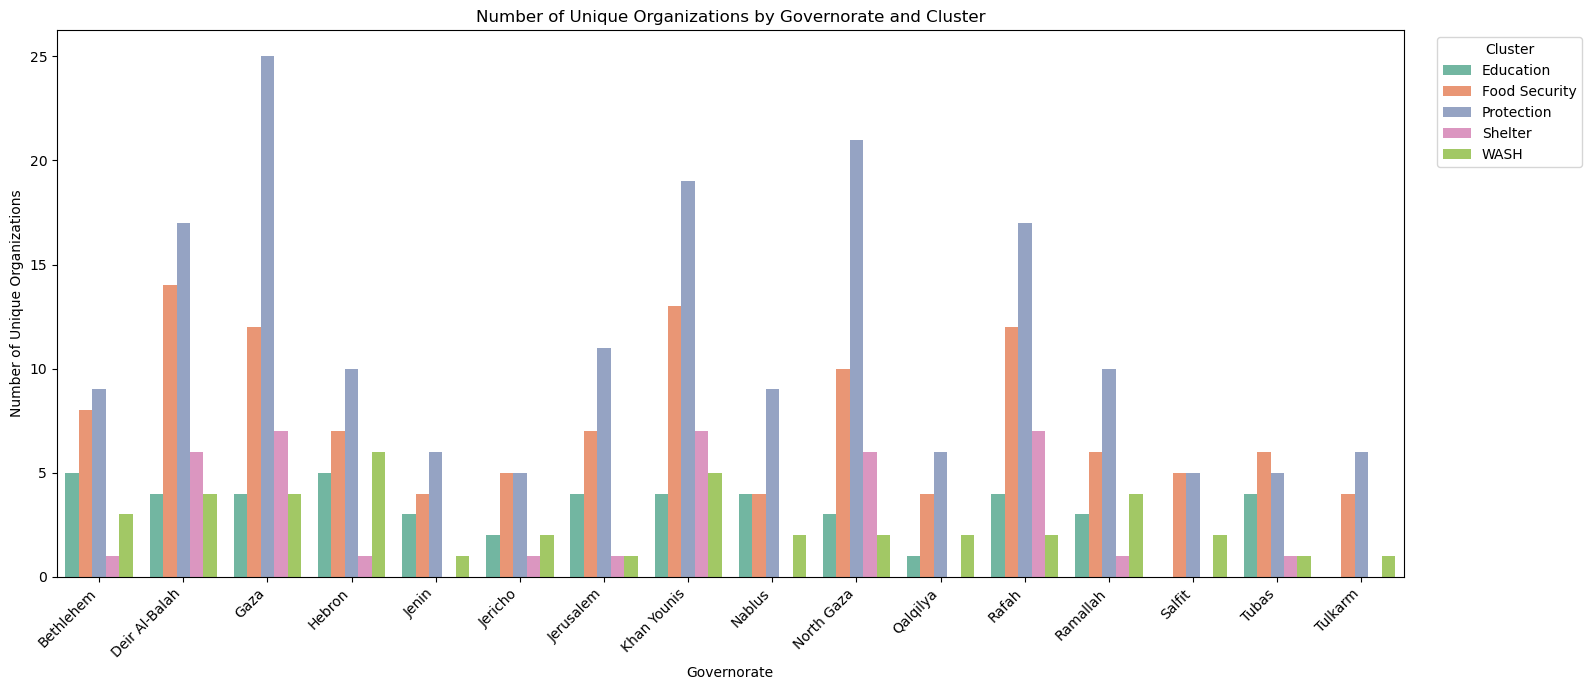

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate data
plot_df = (
    df_3w.groupby(['Governorates', 'Cluster'])['Organization']
    .nunique()
    .reset_index(name='Unique Organizations')
)

# Plot
plt.figure(figsize=(16, 7))

sns.barplot(
    data=plot_df,
    x='Governorates',
    y='Unique Organizations',
    hue='Cluster',
    palette='Set2'
)

plt.xlabel('Governorate')
plt.ylabel('Number of Unique Organizations')
plt.title('Number of Unique Organizations by Governorate and Cluster')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Mean Orgs Per Cluster (Across Govs)

In [51]:
mean_orgs = (
    df_3w.groupby(['Governorates', 'Cluster'])['Organization']
    .nunique()
    .groupby('Cluster')
    .mean()
    .reset_index(name='Mean Organizations')
)

print(mean_orgs)

         Cluster  Mean Organizations
0      Education            3.571429
1  Food Security            7.562500
2     Protection           11.312500
3        Shelter            3.545455
4           WASH            2.625000


## Geoprocessing

## Export Results